# 06 - Final evaluation on the out-of-time test set

Reads outputs of `scripts/evaluate_model.py`. The test set (2014 H2) was not used for any
fitting, tuning, calibration or threshold choice.

> Notebooks display **aggregates only** (no individual loan records) and reuse functions from `src/creditiq/`. Educational project - not for real lending decisions.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from creditiq.config import load_config, setup_logging
from creditiq.cli import processed_path, clean_all_path
from creditiq.reporting import figures as figs

setup_logging("WARNING")
cfg = load_config()
figs.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
TARGET = cfg["target"]["name"]

In [2]:
from creditiq.reporting.results import load_results
res = load_results(cfg.path("models_dir"), cfg.path("metrics_dir"), "applicant")
print(res["summary"])
display(res["test_metrics"])
display(res["bootstrap_ci"])

{'auc_diff_lightgbm_minus_logreg': {'point': 0.0029339695964569756, 'lower': 0.0013634946712304061, 'upper': 0.004234635043379728}, 'feature_set': 'applicant', 'selected_model': 'lightgbm', 'selected_threshold': 0.20223597869029325, 'selected_calibration': 'sigmoid', 'test_n': 123634, 'test_prevalence': 0.1912499797790252, 'test_period': ['2014-07-01', '2014-12-01'], 'decision_assumptions': {'lgd': 0.85, 'ead_fraction': 1.0, 'profit_rate_good_loan': 0.12}, 'decision_breakeven_pd': 0.12371134020618557, 'assumptions_are_hypothetical': True}


,model,variant,n,prevalence,mean_predicted,roc_auc,pr_auc,brier,log_loss,ece,threshold,precision,recall,f1,false_positive_rate,flagged_rate,tn,fp,fn,tp
0,dummy,raw,123634,0.19125,0.157665,0.500000,0.191250,0.155801,0.492056,0.033585,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,dummy,calibrated (none),123634,0.19125,0.157665,0.500000,0.191250,0.155801,0.492056,0.033585,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,99989.0,0.0,23645.0,0.0
2,lightgbm,raw,123634,0.19125,0.160870,0.698345,0.350081,0.143725,0.452665,0.030688,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,lightgbm,calibrated (sigmoid),123634,0.19125,0.184067,0.698345,0.350081,0.142293,0.448898,0.007272,0.202236,0.311902,0.589638,0.407989,0.307614,0.361551,69231.0,30758.0,9703.0,13942.0
4,logistic_regression,raw,123634,0.19125,0.160838,0.695411,0.348187,0.144053,0.454050,0.030466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,logistic_regression,calibrated (sigmoid),123634,0.19125,0.184093,0.695411,0.348187,0.142581,0.450159,0.007157,0.188153,0.304577,0.620850,0.408669,0.335217,0.389844,66471.0,33518.0,8965.0,14680.0


,model,metric,point,lower,upper,reps
0,lightgbm,roc_auc,0.698345,0.694867,0.702082,200
1,lightgbm,pr_auc,0.350081,0.345170,0.355431,200
2,lightgbm,brier,0.142293,0.140891,0.143600,200
3,logistic_regression,roc_auc,0.695411,0.692035,0.698902,200
4,logistic_regression,pr_auc,0.348187,0.342716,0.353809,200
5,logistic_regression,brier,0.142581,0.141102,0.143823,200


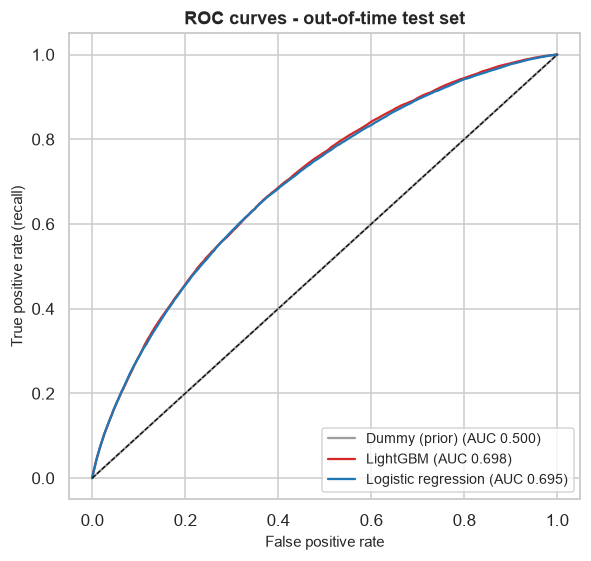

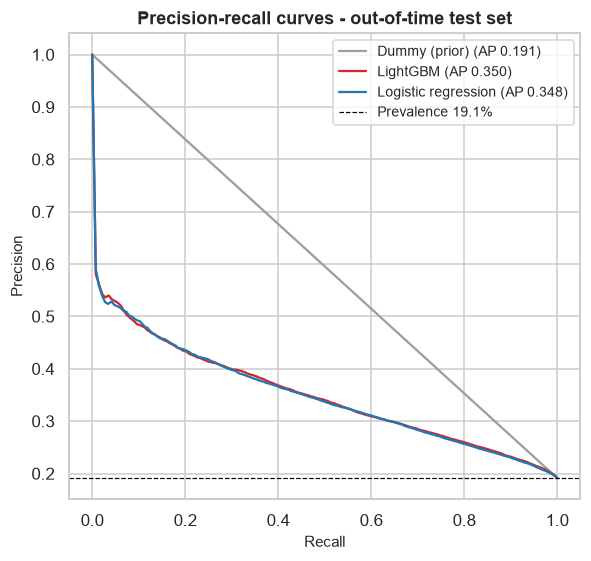

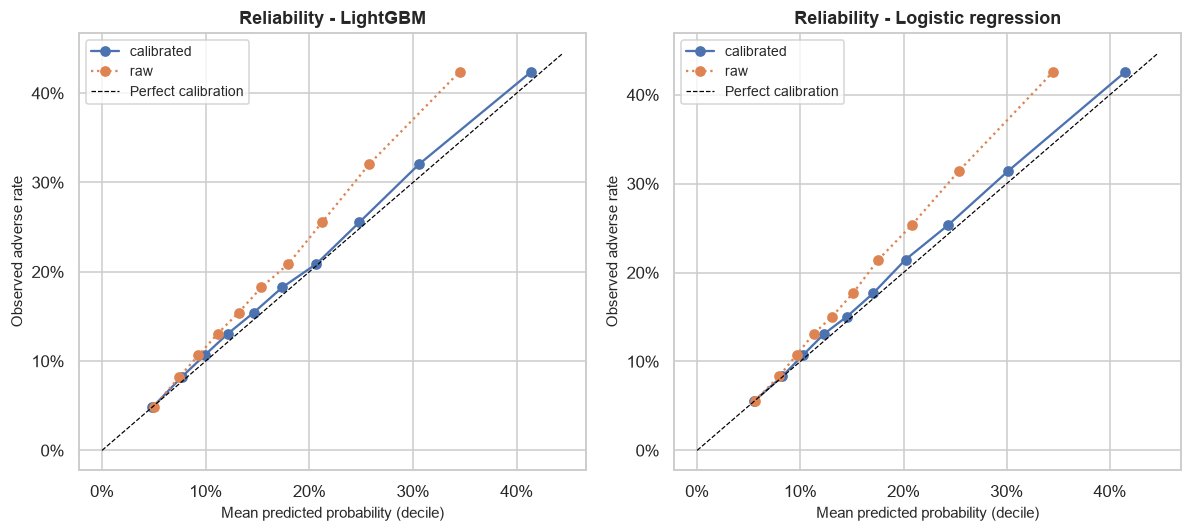

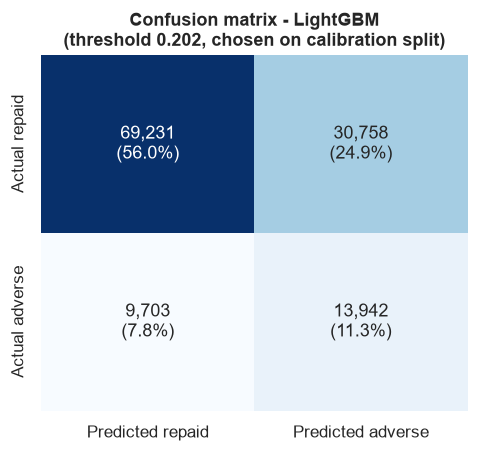

In [3]:
tm = res["test_metrics"]; cal = tm[tm["variant"].str.startswith("calibrated")].set_index("model")
figs.plot_roc_curves(res["roc_curves"], cal["roc_auc"].to_dict()); plt.show()
figs.plot_pr_curves(res["pr_curves"], cal["pr_auc"].to_dict(), res["summary"]["test_prevalence"]); plt.show()
figs.plot_reliability(res["calibration_tables"]); plt.show()
sel = res["metadata"]["selected_model"]; r = cal.loc[sel]
figs.plot_confusion(int(r.tn), int(r.fp), int(r.fn), int(r.tp), float(r.threshold), sel); plt.show()

## Headline caveat: excluded unresolved loans

Loans issued in the test window that were still unresolved at the snapshot (60-month
survivors) were excluded. Here they are scored and added back under explicit labelling
scenarios. The 'all adverse' row is an implausible extreme bound.

In [4]:
from creditiq.reporting.markdown import bias_paragraph
display(res["unresolved_bounds"][["model", "scenario", "n", "prevalence", "mean_predicted", "roc_auc", "brier", "prevalence_60m", "mean_predicted_60m"]])
display(Markdown(bias_paragraph(res)))

,model,scenario,n,prevalence,mean_predicted,roc_auc,brier,prevalence_60m,mean_predicted_60m
0,lightgbm,reported: unresolved excluded,123634,0.191250,0.184067,0.698345,0.142293,0.328447,0.299732
1,lightgbm,all unresolved repaid,132870,0.177956,0.191825,0.670779,0.139206,0.256656,0.298846
2,lightgbm,"Current/Grace repaid, Late adverse",132870,0.180026,0.191825,0.673686,0.139929,0.263164,0.298846
3,lightgbm,all unresolved adverse (extreme bound),132870,0.247467,0.191825,0.731902,0.167612,0.475234,0.298846
4,logistic_regression,reported: unresolved excluded,123634,0.191250,0.184093,0.695411,0.142581,0.328447,0.298701
5,logistic_regression,all unresolved repaid,132870,0.177956,0.192109,0.666817,0.139666,0.256656,0.298857
6,logistic_regression,"Current/Grace repaid, Late adverse",132870,0.180026,0.192109,0.669833,0.140368,0.263164,0.298857
7,logistic_regression,all unresolved adverse (extreme bound),132870,0.247467,0.192109,0.732456,0.167552,0.475234,0.298857


9,236 loans issued in the test window were excluded as unresolved (concentrated in 2014 60-month vintages). They are survivors at the snapshot, so excluding them enriches the remaining 60-month loans with charge-offs. Scoring them with the selected model (lightgbm) and adding them back:

* realistic labelling (Current/Grace repaid, Late adverse): ROC-AUC **0.6737** (reported 0.6983); adverse prevalence 0.1800 vs mean calibrated prediction 0.1918; 60-month loans: observed 0.2632 vs predicted 0.2988;
* all unresolved repaid: ROC-AUC 0.6708;
* extreme bound (all unresolved adverse - implausible): ROC-AUC 0.7319.

On fully resolved 36-month loans (no exclusion bias) the ROC-AUC is **0.6530** with mean prediction 0.1419 vs observed 0.1413.

**Interpretation:** the reported test ROC-AUC (0.6983) is optimistic; a realistic estimate is about 0.674. On the reported test set 60-month loans appear under-predicted (observed 0.328 vs predicted 0.300); with realistic labels they are over-predicted (observed 0.263 vs predicted 0.299). The calibrator was fitted on 2014 Q2, which shares the same exclusion bias.

## Robustness: 36-month subset, quarterly stability, random vs out-of-time split

In [5]:
display(res["sensitivity_36_month"][["model", "population", "n", "prevalence", "roc_auc", "pr_auc", "brier", "mean_predicted"]])
display(res["metrics_by_quarter"][["model", "issue_quarter", "n", "prevalence", "roc_auc", "mean_predicted"]])
display(res["random_split_benchmark"])

,model,population,n,prevalence,roc_auc,pr_auc,brier,mean_predicted
0,lightgbm,36-month loans only (fully resolved),90615,0.141257,0.653042,0.223884,0.117153,0.141920
1,lightgbm,all resolved test loans,123634,0.191250,0.698345,0.350081,0.142293,0.184067
2,logistic_regression,36-month loans only (fully resolved),90615,0.141257,0.647088,0.219587,0.117547,0.142331
3,logistic_regression,all resolved test loans,123634,0.191250,0.695411,0.348187,0.142581,0.184093


,model,issue_quarter,n,prevalence,roc_auc,mean_predicted
0,lightgbm,2014Q3,55238,0.188095,0.701529,0.184217
1,lightgbm,2014Q4,68396,0.193798,0.695843,0.183945
2,logistic_regression,2014Q3,55238,0.188095,0.699229,0.184811
3,logistic_regression,2014Q4,68396,0.193798,0.692449,0.183513


,design,test_n,roc_auc
0,out-of-time split (configured issue-date bound...,123634,0.698345
1,stratified random split (all vintages),102819,0.689432


## Segment analysis (descriptive; not a fairness certification)

,segment,segment_label,group,n,observed_adverse_rate,mean_predicted,calibration_gap,roc_auc,recall,false_positive_rate,flagged_rate,small_sample
0,credit_history_band,Credit history (years),0 - <5,2592,0.224151,0.216803,-0.007348,0.636125,0.645439,0.454998,0.497685,False
1,credit_history_band,Credit history (years),5 - <10,17885,0.207884,0.200269,-0.007615,0.683902,0.604895,0.354980,0.406933,False
2,credit_history_band,Credit history (years),10 - <15,40873,0.199716,0.196554,-0.003162,0.695614,0.626608,0.340660,0.397769,False
3,credit_history_band,Credit history (years),15 - <20,30208,0.188659,0.178533,-0.010126,0.698037,0.571153,0.291934,0.344611,False
4,credit_history_band,Credit history (years),>= 20,32076,0.170969,0.161687,-0.009282,0.710386,0.537564,0.245036,0.295049,False
5,emp_length,Employment length,< 1 year,9923,0.201451,0.188720,-0.012731,0.690715,0.598299,0.319157,0.375391,False
6,emp_length,Employment length,1 year,7952,0.191273,0.182594,-0.008679,0.680853,0.548981,0.298243,0.346202,False
7,emp_length,Employment length,2 years,11042,0.182938,0.181246,-0.001692,0.684666,0.567327,0.304035,0.352201,False
8,emp_length,Employment length,3 years,9681,0.185415,0.181567,-0.003848,0.691052,0.572145,0.302181,0.352236,False
9,emp_length,Employment length,4 years,7414,0.182358,0.180203,-0.002155,0.703190,0.573964,0.289838,0.341651,False


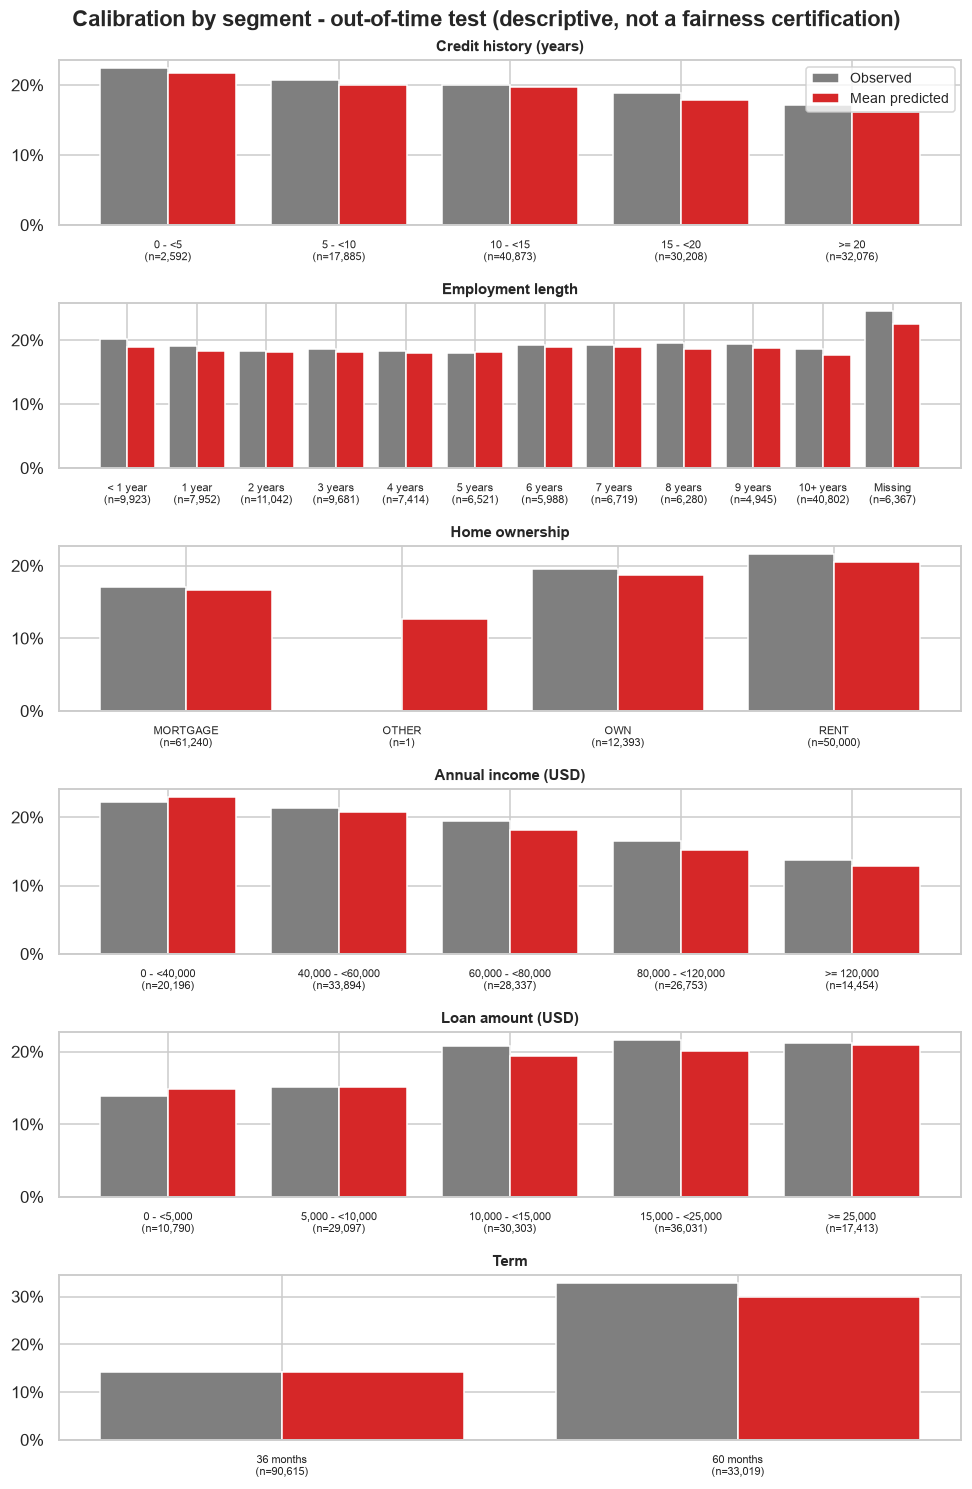

In [6]:
display(res["segment_performance"])
figs.plot_segment_gaps(res["segment_performance"]); plt.show()

## Hypothetical decision simulation

HYPOTHETICAL assumptions: {'lgd': 0.85, 'ead_fraction': 1.0, 'profit_rate_good_loan': 0.12}


,scenario,threshold,approval_rate,n_approved,approved_volume,observed_bad_rate_approved,observed_bad_rate_rejected,expected_loss_approved,false_approval_cost,false_rejection_opportunity_cost,profit_from_good_approvals,net_value
0,approve all,1.000,1.000000,123634,1.792636e+09,0.191250,NaN,2.989488e+08,3.123919e+08,0.0,171013881.0,-1.413780e+08
1,PD < 0.050,0.050,0.048579,6006,8.549870e+07,0.038129,0.199068,2.837489e+06,2.779691e+06,161146464.0,9867417.0,7.087726e+06
2,PD < 0.075,0.075,0.141644,17512,2.465782e+08,0.056304,0.213518,1.148990e+07,1.156795e+07,143057613.0,27956268.0,1.638832e+07
3,PD < 0.100,0.100,0.255520,31591,4.355796e+08,0.073755,0.231577,2.555057e+07,2.675643e+07,122521701.0,48492180.0,2.173575e+07
4,PD < 0.125,0.125,0.365757,45220,6.145927e+08,0.087771,0.250925,4.263154e+07,4.516836e+07,103639464.0,67374417.0,2.220605e+07
5,PD < 0.150,0.150,0.463659,57324,7.702962e+08,0.099749,0.270351,6.078821e+07,6.425322e+07,87649383.0,83364498.0,1.911128e+07
6,PD < 0.175,0.175,0.554451,68549,9.174358e+08,0.111351,0.290678,8.107893e+07,8.571978e+07,73023204.0,97990677.0,1.227090e+07
7,PD < 0.200,0.200,0.632407,78187,1.047529e+09,0.122092,0.310229,1.018044e+08,1.080739e+08,60567888.0,110445993.0,2.372106e+06
8,PD < 0.250,0.250,0.755480,93403,1.265994e+09,0.139000,0.352684,1.434439e+08,1.513406e+08,40460337.0,130553544.0,-2.078704e+07
9,PD < 0.300,0.300,0.843231,104252,1.437926e+09,0.153417,0.394748,1.834790e+08,1.927960e+08,25681014.0,145332867.0,-4.746309e+07


,lgd,profit_rate_good_loan,breakeven_pd,best_scenario,best_threshold,best_approval_rate,best_net_value,approve_all_net_value
0,0.60,0.06,0.090909,PD < 0.075,0.075,0.141644,5812524.00,-1.350050e+08
1,0.60,0.09,0.130435,PD < 0.125,0.125,0.365757,18647262.75,-9.225150e+07
2,0.60,0.12,0.166667,PD < 0.150,0.150,0.463659,38009283.00,-4.949803e+07
3,0.60,0.15,0.200000,PD < 0.175,0.175,0.554451,61980266.25,-6.744559e+06
4,0.75,0.06,0.074074,PD < 0.075,0.075,0.141644,3771121.50,-1.901329e+08
5,0.75,0.09,0.107143,PD < 0.100,0.100,0.255520,12760522.50,-1.473795e+08
6,0.75,0.12,0.137931,PD < 0.125,0.125,0.365757,27519979.50,-1.046260e+08
7,0.75,0.15,0.166667,PD < 0.150,0.150,0.463659,47511603.75,-6.187254e+07
8,0.85,0.06,0.065934,PD < 0.075,0.075,0.141644,2410186.50,-2.268849e+08
9,0.85,0.09,0.095745,PD < 0.100,0.100,0.255520,9612707.50,-1.841315e+08


,bucket,n,mean_predicted_pd,observed_adverse_rate,volume,expected_loss,share,expected_loss_rate
0,A - Very low,20200,0.057891,0.060198,283724275.0,1.393649e+07,0.163385,0.049120
1,B - Low,32482,0.109103,0.116772,426818375.0,3.948891e+07,0.262727,0.092519
2,C - Moderate,32090,0.177055,0.183764,428949475.0,6.478688e+07,0.259556,0.151036
3,D - High,22919,0.264293,0.272263,357589575.0,8.084982e+07,0.185378,0.226097
4,E - Very high,15943,0.395447,0.407640,295553825.0,9.988671e+07,0.128953,0.337965


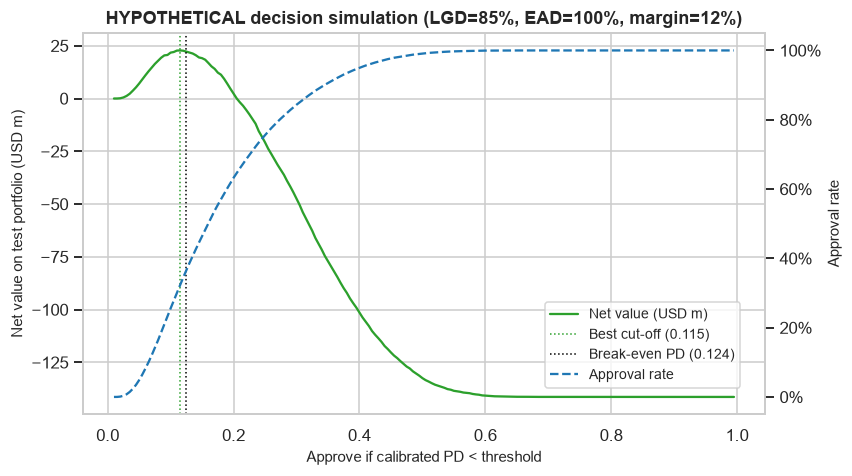

In [7]:
a = res["summary"]["decision_assumptions"]; print("HYPOTHETICAL assumptions:", a)
display(res["decision_scenarios"])
display(res["decision_sensitivity"])
display(res["risk_buckets"])
figs.plot_decision_curve(res["decision_curve"], a["lgd"], a["ead_fraction"], a["profit_rate_good_loan"],
                         chosen=res["summary"]["decision_breakeven_pd"]); plt.show()

## Applicant vs origination feature sets

In [8]:
orig = load_results(cfg.path("models_dir"), cfg.path("metrics_dir"), "origination")
both = pd.concat([res["bootstrap_ci"].assign(feature_set="applicant"), orig["bootstrap_ci"].assign(feature_set="origination")])
display(both[both["metric"] == "roc_auc"])

,model,metric,point,lower,upper,reps,feature_set
0,lightgbm,roc_auc,0.698345,0.694867,0.702082,200,applicant
3,logistic_regression,roc_auc,0.695411,0.692035,0.698902,200,applicant
0,lightgbm,roc_auc,0.715043,0.711269,0.718545,200,origination
3,logistic_regression,roc_auc,0.711566,0.707951,0.715197,200,origination
